## 이미지 전이학습


In [2]:
from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
print("torch:", torch.__version__, "torchvision:", torchvision.__version__)


torch: 2.15.0+cpu torchvision: 0.29.2+cpu


### 전이학습이란

전이학습(Transfer Learning)은 다른 데이터로 학습한 모델의 지식을 새로운 문제에 재사용하는 학습 방법이다. 이미지 분류에서는 기존 모델이 학습한 특징 추출 능력을 가져와 새로운 종류의 이미지를 구분하는 데 활용한다.

모델을 기존 데이터로 미리 학습하는 과정을 사전학습이라고 한다. 학습 중에는 예측이 정답에 가까워지도록 가중치가 조정되고, 이미지에서 유용한 특징을 찾아내는 능력이 이 가중치에 반영된다. 이렇게 학습을 마친 가중치가 사전학습 가중치다. 저장된 가중치를 모델에 불러오면 이미 학습한 상태에서 새로운 학습을 시작할 수 있다.

예를 들어 다양한 사진으로 사전학습한 이미지 모델은 모서리·질감·형태 같은 특징을 추출할 수 있다. 이런 특징은 새로운 이미지에서도 대상을 구분하는 데 도움이 되므로, 이미 학습한 특징 추출 능력을 재사용할 수 있다.

새로운 문제에 적용할 때는 사전학습된 가중치를 가져오고, 출력이 새 데이터의 클래스에 맞도록 모델을 수정한다. 이후 새 이미지와 정답으로 학습하면서 기존 특징을 분류에 활용하는 방법을 익힌다. 필요한 경우에는 특징을 추출하는 부분도 함께 조정한다. 전이학습에서 재사용하는 것은 기존 학습으로 얻은 가중치이며, 새로운 문제에 맞춘 학습은 새 데이터로 이루어진다.

### 백본과 분류 헤드

이미지 분류 모델은 사진에서 특징을 추출하고, 그 특징으로 각 클래스의 점수를 계산한다. 특징을 추출하는 부분을 백본(backbone), 각 클래스의 점수를 계산하는 마지막 부분을 분류 헤드(classification head)라고 부른다.

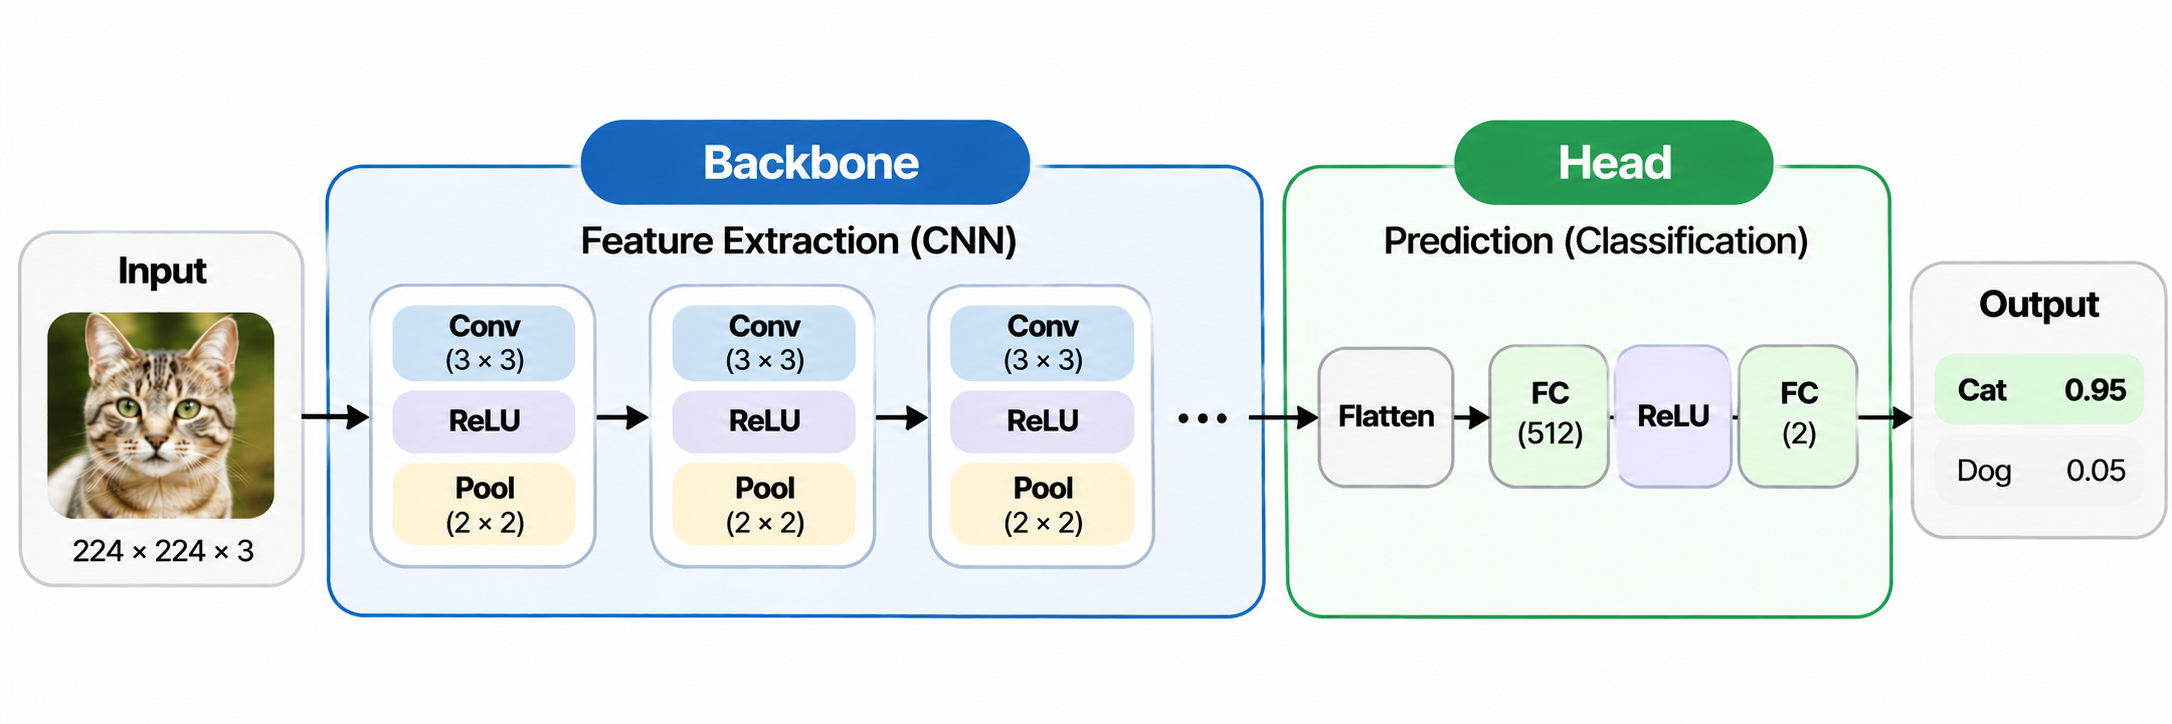

새로운 이미지 분류 문제에 적용하려면 사전학습된 백본을 가져오고, 기존 클래스의 점수를 계산하던 분류 헤드를 새 데이터의 클래스 수에 맞는 분류 헤드로 교체한다. 새 분류 헤드는 무작위 가중치에서 시작해 새로운 이미지와 정답으로 학습한다.

## 전이학습의 두 가지 방식

### 특징 추출 방식

특징 추출(Feature Extraction) 방식은 사전학습된 백본의 가중치를 고정하고 새 분류 헤드만 학습한다. 가중치를 학습 중에 바꾸지 않도록 고정하는 것을 동결이라고 한다.

백본은 이미지의 특징을 추출하고, 새 분류 헤드는 그 특징을 이용해 새로운 데이터의 클래스를 구분하는 방법을 학습한다. 학습할 파라미터가 적어 상대적으로 빠르고, 데이터가 적을 때 유리할 수 있다.

### 미세 조정 방식

미세 조정(Fine-tuning) 방식은 새 분류 헤드와 함께 사전학습된 백본의 일부 또는 전체 가중치도 학습하는 방식이다. 새 데이터에 맞게 특징을 추출하는 방법까지 조정한다.

사전학습된 가중치가 한 번에 크게 바뀌지 않도록 작은 학습률을 사용한다. 백본에서 어느 부분까지 학습할지는 조절할 수 있는 조건이다.

| 학습 방식 | 백본의 시작 가중치 | 가중치를 갱신하는 범위 |
| --- | --- | --- |
| 처음부터 학습 | 무작위 초기화 | 백본과 분류 헤드 전체 |
| 특징 추출 | 사전학습 가중치 | 새 분류 헤드만 |
| 미세 조정 | 사전학습 가중치 | 분류 헤드와 백본의 일부 또는 전체 |

### 사전학습 가중치를 사용하는 이유

전이학습은 이미 학습된 특징을 활용하므로, 처음부터 학습할 때보다 적은 데이터와 짧은 학습 시간으로도 좋은 성능을 얻을 수 있다. 효과는 사전학습 데이터와 새 데이터의 특성, 데이터의 양, 학습 범위 등에 따라 달라진다.

사전학습한 특징이 새 문제에 잘 맞지 않으면 성능 향상이 작을 수 있다. 기존 지식을 활용한 것이 오히려 새 문제의 성능을 떨어뜨리는 현상을 부정적 전이라고 한다.

### 전이학습과 역전파

전이학습도 순전파로 예측을 계산하고, 정답과의 차이를 손실로 구한 뒤, 역전파로 기울기를 계산해 가중치를 갱신한다.

순전파 → 손실 계산 → 역전파 → 가중치 갱신

동결된 가중치는 유지하고, 학습하도록 설정한 파라미터는 옵티마이저가 기울기를 이용해 갱신한다. 특징 추출 방식에서는 새 분류 헤드가, 미세 조정 방식에서는 분류 헤드와 선택한 백본 부분이 갱신 대상이다.


### 개미·벌 분류

개미 또는 벌이 담긴 사진을 입력으로 받아 두 종류 중 하나로 분류하는 문제다.
이 문제에는 ImageNet으로 사전학습된 CNN 모델인 ResNet18을 사용한다.

### 개미·벌 데이터

한 사례는 개미 또는 벌이 담긴 RGB 사진 한 장이다. 배경·자세·크기가 다양하다.
배포본은 `train` 폴더 244장과 `val` 폴더 153장으로 구성된다.

ImageNet에서 가져온 소규모 데이터이며, 점수는 이 실습 데이터 안에서 두 학습 방식을 비교하는 데 사용한다.


In [3]:
data_root = Path("image_data")
image_root = data_root / "hymenoptera_data"
if not image_root.exists():  # 저장된 폴더가 없을 때만 다운로드하고 압축을 푼다.
    download_and_extract_archive(
        "https://download.pytorch.org/tutorial/hymenoptera_data.zip",
        download_root=str(data_root),
    )

# ImageFolder는 하위 폴더 이름순으로 클래스 번호를 정한다. 한 항목은 (PIL 이미지, 정수 라벨)이다.
source_train = ImageFolder(image_root / "train")
source_holdout = ImageFolder(image_root / "val")  # 검증·테스트로 나눌 데이터
classes = source_train.classes  # 클래스 번호 순서의 이름 목록

print("클래스 번호:", source_train.class_to_idx)
print("원본 이미지 수:", len(source_train), len(source_holdout))


100%|██████████| 47.3M/47.3M [00:01<00:00, 41.0MB/s]


클래스 번호: {'ants': 0, 'bees': 1}
원본 이미지 수: 244 153


### 학습·검증·테스트 분리

`train` 폴더의 244장은 학습에 사용하고, `val` 폴더의 153장은 클래스 비율을 유지하며 검증 76장과 테스트 77장으로 나눈다.


In [4]:
# targets는 사진별 정답 번호다. 분리에 사용할 정답과 인덱스는 NumPy 배열로 준비한다.
train_targets = np.array(source_train.targets)
holdout_targets = np.array(source_holdout.targets)
train_idx = np.arange(len(source_train))  # 0부터 마지막 사진까지의 인덱스

# 이미지 대신 인덱스를 나눈다. stratify는 클래스 비율을 유지한다.
val_idx, test_idx = train_test_split(
    np.arange(len(source_holdout)), test_size=0.5,
    stratify=holdout_targets, random_state=SEED,
)

split_targets = {"train": train_targets,
                 "validation": holdout_targets[val_idx], "test": holdout_targets[test_idx]}

# bincount는 클래스 번호별 사진 수를 센다.
class_counts = pd.DataFrame({
    name: np.bincount(labels, minlength=len(classes)) for name, labels in split_targets.items()
}, index=classes)
display(class_counts)


,train,validation,test
ants,123,35,35
bees,121,41,42


### 학습 이미지 살펴보기

학습에 사용할 사진 네 장과 각 사진의 분류 라벨을 확인한다.


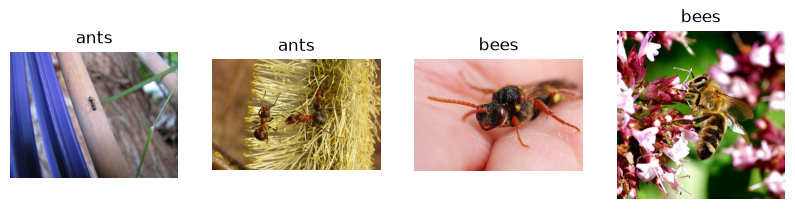

In [5]:
# 같은 시드로 사진 네 장을 중복 없이 고른다.
preview_idx = np.random.default_rng(SEED).choice(train_idx, size=4, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, index in zip(axes, preview_idx):
    image, label = source_train[int(index)]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()


### 이미지 전처리

사전학습 가중치에 맞는 기본 전처리를 사용한다.


In [6]:
weights = ResNet18_Weights.DEFAULT  # 사전학습된 ResNet18 가중치
image_transform = weights.transforms()  # 해당 가중치에 맞는 기본 전처리

# transform은 ImageFolder가 사진을 꺼낼 때 적용된다. 정답은 정수 클래스 번호다.
train_images = ImageFolder(image_root / "train", transform=image_transform)
holdout_images = ImageFolder(image_root / "val", transform=image_transform)

# Subset은 지정한 인덱스만 선택하고, DataLoader는 최대 32개씩 텐서 배치로 묶는다.
raw_val = DataLoader(Subset(holdout_images, val_idx), batch_size=32)
raw_test = DataLoader(Subset(holdout_images, test_idx), batch_size=32)

def make_image_train_loader():
    # shuffle로 학습 순서를 섞고, 두 모델의 순서가 같도록 매번 같은 시드로 시작한다.
    return DataLoader(Subset(train_images, train_idx), batch_size=32, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

raw_train = make_image_train_loader()
images, labels = next(iter(raw_train))  # 첫 배치: 이미지 (B, 3, 224, 224), 정답 (B,)
print("이미지·정답 모양:", images.shape, labels.shape)


이미지·정답 모양: torch.Size([32, 3, 224, 224]) torch.Size([32])


## 사전학습 모델 준비

### ResNet18의 구조

ResNet18은 합성곱으로 이미지의 특징을 추출한 뒤, 마지막 완전연결층에서 클래스별 점수를 계산한다. 입력이 통과하는 순서는 다음과 같다.

| 구성 | 역할 |
| --- | --- |
| `conv1` → `bn1` → `relu` | 합성곱으로 특징을 추출하고, BatchNorm으로 값의 분포를 조절한 뒤 활성화 함수를 적용한다. |
| `maxpool` | 특징 맵의 가로·세로 크기를 줄인다. |
| `layer1` → `layer2` → `layer3` → `layer4` | 각 단계에 묶인 합성곱·BatchNorm·활성화 함수를 거치며 특징을 가공한다. |
| `avgpool` | 각 특징 맵의 공간 방향 평균을 구해 채널마다 하나의 값으로 요약한다. |
| 펼치기 | 요약된 특징을 사진별로 한 줄로 정리한다. |
| `fc` | 정리된 특징으로 클래스별 점수를 계산한다. |

`conv1`은 입력 이미지에 처음 적용하는 합성곱 층 하나다. `layer1`부터 `layer4`는 여러 층을 묶은 처리 단계의 이름이며, 앞 단계에서 나온 특징을 받아 추가로 가공한다.

이 모델에서는 `fc` 앞까지가 백본이고, `fc`가 분류 헤드다.


In [7]:
torch.manual_seed(SEED)
initial_model = resnet18(weights=weights)  # 지정한 사전학습 가중치를 불러온다.
print(initial_model)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\student/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 76.0MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

### 백본 동결과 분류 헤드 교체

`fc`는 완전연결층(fully connected layer)을 뜻하며, ResNet18에서는 `nn.Linear`로 구현된 분류 헤드의 이름이다. 입력 특징 각각에 가중치를 곱해 합하고 편향을 더하여 클래스별 점수를 계산한다.

ResNet18의 백본이 추출한 특징은 사진 한 장당 512개의 값으로 정리되어 `fc`에 전달된다. 기존 `fc`를 개미·벌 점수 두 개를 계산하는 새 선형층으로 교체한다.

두 학습 방식이 같은 가중치에서 시작하도록 이 초기 모델을 보관하고, 각 방식에 사용할 모델을 복사한다. 특징 추출 방식에서는 복사한 모델의 백본을 동결하고 `fc`만 학습하도록 설정한다.


In [ ]:
# fc.in_features는 입력 특징 수(512)다. 출력 수는 데이터의 클래스 수에 맞춘다.
initial_model.fc = nn.Linear(initial_model.fc.in_features, len(classes))

head_model = deepcopy(initial_model)  # 공통 시작 가중치를 유지하면서 독립적인 모델을 복사한다.
head_model.requires_grad_(False)  # 전체 파라미터의 기울기 계산을 끈다.
head_model.fc.requires_grad_(True)  # 새 분류 헤드만 기울기를 계산하고 학습한다.

head_model.eval()
with torch.no_grad():  # 출력 확인에는 기울기 계산이 필요 없다.
    logits = head_model(images[:2])  # 사진 2장의 클래스별 점수: (2, 2), 행은 사진·열은 클래스
print("분류 출력 모양:", logits.shape)


분류 출력 모양: torch.Size([2, 2])


## 공통 학습·평가 함수

특징 추출 방식과 전체 미세 조정 방식은 같은 학습·평가 함수를 사용한다. 모델별 학습 범위는 동결 설정으로 구분한다.


In [17]:
def train_one_epoch(model, loader, optimizer):
    model.train()  # 모델을 학습 모드로 설정한다.

    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:
        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, labels)  # 클래스 점수 (B, C)와 정답 번호 (B,)로 손실 계산

        optimizer.zero_grad()  # 이전 배치의 기울기를 지운다.
        loss.backward()  # 학습할 파라미터의 기울기 계산
        optimizer.step()  # 계산한 기울기로 파라미터 갱신

        loss_sum += loss.item() * len(labels)  # 배치 평균 손실을 사진 수만큼 가중해 합산한다.
        correct += (logits.argmax(dim=1) == labels).sum().item()  # 가장 큰 점수의 클래스 번호로 정답 수를 센다.
        count += len(labels)

    return loss_sum / count, correct / count


### 검증 손실과 정확도 계산

모델을 평가 모드로 두고 검증 이미지의 손실과 정확도를 계산한다.
검증에서는 기울기를 계산하거나 가중치를 갱신하지 않는다.


In [18]:
@torch.no_grad()  # 함수 전체에서 기울기 계산을 끈다.
def evaluate_classifier(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:
        logits = model(inputs)
        loss_sum += nn.functional.cross_entropy(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)

    return loss_sum / count, correct / count


### 반복 학습과 최적 가중치 보관

학습 가능한 파라미터만 옵티마이저에 전달하고, 각 에포크의 학습·검증 손실과 정확도를 기록한다.
검증 손실이 가장 작은 에포크의 가중치를 보관했다가 학습이 끝나면 복원한다.


In [19]:
def fit_classifier(model, train_loader, val_loader, epochs, lr):
    # requires_grad=True인 파라미터만 갱신한다. lr은 학습률이다.
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)

    history = []
    best_loss, best_state = float("inf"), None

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate_classifier(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": train_loss,
                        "val_loss": val_loss, "train_accuracy": train_acc, "val_accuracy": val_acc})

        if val_loss < best_loss:
            # state_dict의 파라미터와 저장 통계를 복사해 이후 학습에도 이 상태를 보존한다.
            best_loss, best_state = val_loss, deepcopy(model.state_dict())

        print(f"epoch={epoch+1} train_loss={train_loss:.3f} val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    model.load_state_dict(best_state)  # 검증 손실이 가장 작았던 상태로 복원한다.
    model.eval()
    return pd.DataFrame(history)


## 특징 추출 방식: 분류 헤드 학습

새 분류 헤드의 가중치는 무작위로 시작한다. 백본의 가중치를 고정하고 새 분류 헤드가 그 특징을 개미·벌 정답에 연결하도록 학습한다.

백본을 동결한 상태에서 새 분류 헤드를 5에포크 학습한다. Adam의 학습률은 0.001이다.
학습·검증 손실과 정확도를 기록하고 검증 손실이 가장 낮은 가중치를 복원한다.


In [20]:
HEAD_EPOCHS = 5

feature_history = fit_classifier(head_model, make_image_train_loader(), raw_val,
                              epochs=HEAD_EPOCHS, lr=0.001)


epoch=1 train_loss=0.608 val_loss=0.461 val_acc=0.842
epoch=2 train_loss=0.414 val_loss=0.326 val_acc=0.921
epoch=3 train_loss=0.313 val_loss=0.266 val_acc=0.947
epoch=4 train_loss=0.275 val_loss=0.229 val_acc=0.961
epoch=5 train_loss=0.213 val_loss=0.211 val_acc=0.974


## 미세 조정 방식: 전체 가중치 학습

미세 조정은 분류 헤드와 함께 백본의 가중치도 새로운 데이터에 맞게 조정하는 방식이다. 여기서는 백본 전체를 학습해 이미지에서 특징을 추출하는 방법과 그 특징으로 분류하는 방법을 함께 조정한다.

`initial_model`은 사전학습된 백본에 새 분류 헤드를 연결해 보관한 초기 모델이다. 이를 복사해 `fine_model`을 만들면 특징 추출 방식과 같은 가중치에서 학습을 시작할 수 있다. 복사한 모델의 모든 파라미터를 학습 가능하게 설정한다.

학습은 5에포크 진행한다. 사전학습된 가중치를 조금씩 조정하도록, 분류 헤드만 학습할 때의 0.001보다 작은 학습률 0.0001을 사용한다.


In [21]:
FINE_TUNE_EPOCHS = 5

fine_model = deepcopy(initial_model)  # 특징 추출 방식과 같은 초기 가중치에서 시작한다.
fine_model.requires_grad_(True)  # 백본과 분류 헤드 전체를 학습한다.

torch.manual_seed(SEED)
fine_history = fit_classifier(fine_model, make_image_train_loader(), raw_val,
                              epochs=FINE_TUNE_EPOCHS, lr=0.0001)


epoch=1 train_loss=0.375 val_loss=0.152 val_acc=0.921
epoch=2 train_loss=0.041 val_loss=0.124 val_acc=0.934
epoch=3 train_loss=0.010 val_loss=0.116 val_acc=0.934
epoch=4 train_loss=0.010 val_loss=0.113 val_acc=0.961
epoch=5 train_loss=0.002 val_loss=0.121 val_acc=0.974


## 전이학습 모델 비교와 선택

### 검증 손실과 정확도로 모델 비교

분류 헤드만 학습한 모델과 전체를 미세 조정한 모델을 비교한다. 시작 가중치·데이터·에포크 수는 같고, 학습 범위와 학습률이 다르다.

정확도는 맞힌 사진의 비율이고, 교차 엔트로피 손실은 각 사진의 정답 클래스에 부여한 확률을 반영한다.
두 지표는 서로 다른 방향으로 변할 수 있다. 여기서는 검증 손실이 가장 작은 모델을 선택한다.


In [22]:
transfer_models = {"head_only": head_model, "fine_tuned": fine_model}
transfer_histories = {"head_only": feature_history, "fine_tuned": fine_history}

rows = []
for name, candidate in transfer_models.items():
    loss, accuracy = evaluate_classifier(candidate, raw_val)

    history = transfer_histories[name]
    best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])  # idxmin은 최솟값이 있는 행의 인덱스
    rows.append({"model": name, "best_epoch": best_epoch, "val_loss": loss, "val_accuracy": accuracy})

transfer_results = pd.DataFrame(rows).sort_values("val_loss")
display(transfer_results)

selected_transfer = str(transfer_results.iloc[0]["model"])  # 검증 손실순 정렬 후 첫 모델 선택
practice_model = transfer_models[selected_transfer]
print("검증 손실로 선택한 모델:", selected_transfer)


,model,best_epoch,val_loss,val_accuracy
1,fine_tuned,4,0.112988,0.960526
0,head_only,5,0.210568,0.973684


검증 손실로 선택한 모델: fine_tuned


### 같은 사진의 예측 비교

검증 사진 네 장의 원본과 정답, 두 모델의 예측을 함께 표시한다. 예측은 원본에 전처리를 적용한 입력으로 계산한 결과다.

사진별 예측이 같은지, 정답과 일치하는지 확인한다. 전체 성능의 변화는 검증 결과 표로 판단한다.


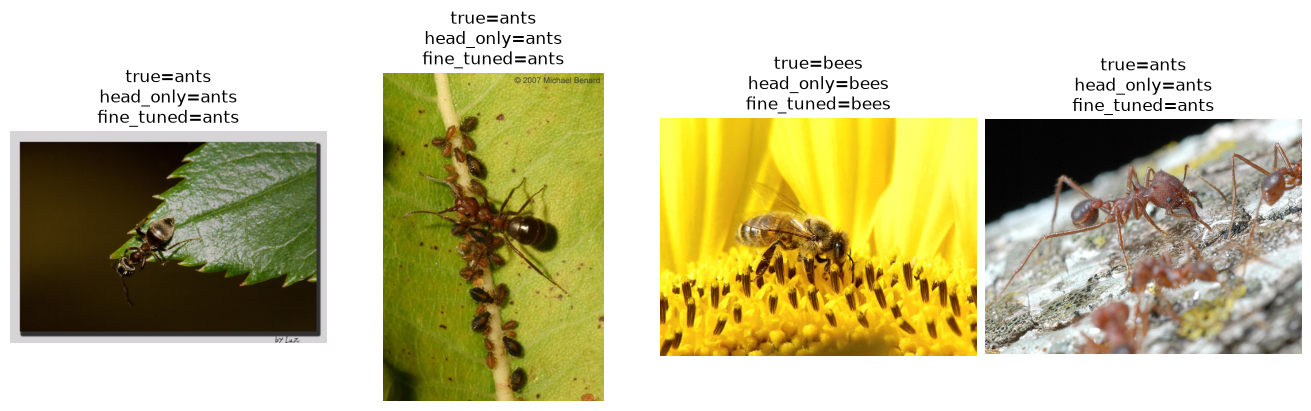

In [23]:
images, labels = next(iter(raw_val))
inputs = images[:4]

head_model.eval()
fine_model.eval()
with torch.no_grad():
    head_predictions = head_model(inputs).argmax(dim=1).cpu()  # 네 사진의 예측 클래스 번호
    fine_predictions = fine_model(inputs).argmax(dim=1).cpu()

fig, axes = plt.subplots(1, 4, figsize=(13, 4), layout="constrained")
for i, ax in enumerate(axes):
    # raw_val은 섞지 않으므로 첫 네 입력은 val_idx[:4]의 사진과 대응한다.
    image, label = source_holdout[int(val_idx[i])]
    ax.imshow(image)
    ax.set_title(f"true={classes[label]}\nhead_only={classes[int(head_predictions[i])]}\nfine_tuned={classes[int(fine_predictions[i])]}")
    ax.axis("off")
plt.show()


### 최종 테스트

검증 결과로 선택한 모델의 테스트 손실과 정확도를 확인한다. 테스트 데이터는 모델 선택을 마친 뒤 최종 평가에 사용한다.


In [24]:
print("선택한 모델:", selected_transfer)
print("test loss, accuracy:", evaluate_classifier(practice_model, raw_test))


선택한 모델: fine_tuned
test loss, accuracy: (0.2495313882102053, 0.922077922077922)


## 연습문제: 다른 이미지 데이터에 전이학습 적용


### 개·고양이 데이터 불러오기

개 또는 고양이가 담긴 사진을 두 클래스로 분류한다. 데이터는 `train` 폴더 2,000장과 `validation` 폴더 1,000장으로 구성된다.

원본 사진을 확인할 데이터와 모델 입력용 전처리를 적용할 데이터를 각각 불러온다.


In [ ]:
cats_root = data_root / "cats_and_dogs_filtered"
if not cats_root.exists():
    download_and_extract_archive(
        "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip",
        download_root=str(data_root),
    )

cats_source_train = ImageFolder(cats_root / "train")
cats_source_holdout = ImageFolder(cats_root / "validation")

cats_train_images = ImageFolder(cats_root / "train", transform=image_transform)
cats_holdout_images = ImageFolder(cats_root / "validation", transform=image_transform)

cats_classes = cats_source_train.classes

print("클래스 번호:", cats_source_train.class_to_idx)
print("학습용 / 검증·테스트 분리용 이미지 수:", len(cats_source_train), len(cats_source_holdout))


100%|██████████| 68.6M/68.6M [00:03<00:00, 20.7MB/s]


클래스 번호: {'cats': 0, 'dogs': 1}
학습용 / 검증·테스트 분리용 이미지 수: 2000 1000


: 

### 직접 작성하기

개·고양이 데이터에 특징 추출 방식과 전체 미세 조정 방식을 각각 적용하고, 두 모델의 검증 손실과 정확도를 비교한다.
